Idiopathic pulmonary fibrosis is a devastating condition, and analyzing a real-world bulk RNA-seq dataset for it provides a powerful, clinically relevant window into complex disease mechanisms. Breaking down the medical terminology reveals exactly what is happening at a tissue level, where "idiopathic" indicates that the underlying trigger remains unknown, "pulmonary" refers to the lungs, and "fibrosis" describes progressive scarring. This pathological scarring stiffens the lung tissue and severely impairs alveolar gas exchange, leading to the grim prognosis of a median survival of only two and a half to three and a half years post-diagnosis and a five-year survival rate between twenty and forty percent. Because there is currently no cure and treatments can only slow down disease progression rather than reverse it, early detection and a deep molecular understanding of the pathways driving fibrosis are critical.

The dataset structured for this project is exceptionally well-designed for a rigorous bioinformatics analysis. It comprises bulk RNA-seq data measuring the mRNA expression levels of 18,838 genes across 103 samples, balanced evenly between IPF conditions and non-IPF controls. This scale gives enough statistical power to detect meaningful transcriptomic shifts while covering a comprehensive set of human genes.

The composition of the samples reflects careful experimental design to account for biological and technical variance. On the disease side, the 103 IPF samples are split between 36 surgical biopsies taken from living patients with confirmed disease and 67 samples extracted from severely diseased lungs removed entirely during transplant surgeries. This captures both earlier-stage active fibrotic remodeling and end-stage architectural destruction.

Meanwhile, the 103 non-IPF control samples provide a robust baseline by incorporating two distinct sources. Forty-one samples come from histologically normal, non-cancerous margins of lung cancer biopsies, while the remaining 62 samples come from deceased organ donors without any history of lung disease. Including both tumor-adjacent normal tissue and healthy donor lungs allows researchers to control for potential confounding factors introduced by the biopsy procedure itself, ensuring that any differentially expressed genes discovered in the analysis truly reflect fibrotic disease processes rather than artifacts of tissue collection or co-morbidities.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

In [41]:
main_df = pd.read_csv("../data/GSE150910/GSE150910_gene-level_count_file.csv")
main_df.head()

,symbol,chp_26,chp_31,chp_34,chp_38,chp_1,chp_3,chp_4,chp_11,chp_5,...,chp_106,chp_108,chp_109,chp_110,chp_111,chp_112,chp_113,chp_114,ipf_1125,ipf_1130
0,TSPAN6,1361,993,351,613,841,565,1093,6239,1714,...,466,638,334,349,778,872,693,465,639,944
1,TNMD,5,13,0,0,0,6,3,4,0,...,0,0,0,0,0,0,0,0,0,0
2,DPM1,1929,2775,1894,2007,1436,1923,1956,4518,2411,...,936,1162,1043,689,1006,870,1701,860,1387,2150
3,SCYL3,176,216,208,218,162,137,242,490,259,...,57,35,122,42,73,68,145,21,146,204
4,C1orf112,93,143,97,148,98,128,102,188,119,...,50,60,72,21,74,48,131,72,69,158


In [42]:
genes = main_df['symbol'].values

In [43]:
set([column_name.split('_')[0] for column_name in main_df.columns.tolist()[1:]])

{'chp', 'control', 'ipf'}

In [44]:
df = main_df.copy()

In [45]:
df = df.filter(regex='control|ipf', axis=1)
df.head()

,ipf_724,ipf_726,ipf_729,ipf_730,ipf_731,ipf_732,ipf_733,ipf_735,control_738,ipf_739,...,control_1092,control_1096,control_1097,control_1102,control_1109,control_1111,control_1112,control_1113,ipf_1125,ipf_1130
0,849,1093,844,2918,1055,1063,3297,1632,2240,940,...,707,566,1338,577,655,1028,780,1092,639,944
1,0,0,0,9,0,3,0,0,0,0,...,0,0,0,0,0,5,0,6,0,0
2,2388,2229,1492,2464,2730,2360,2190,2390,2739,1711,...,2550,2115,2147,2045,2060,2841,2304,2084,1387,2150
3,165,217,148,363,278,328,287,249,330,170,...,335,220,206,213,158,216,257,199,146,204
4,104,161,103,188,212,153,104,143,248,112,...,156,79,96,87,83,192,143,114,69,158


In [46]:
# turn every row and column to float
df = df.apply(pd.to_numeric, axis=1,)
df.head()

,ipf_724,ipf_726,ipf_729,ipf_730,ipf_731,ipf_732,ipf_733,ipf_735,control_738,ipf_739,...,control_1092,control_1096,control_1097,control_1102,control_1109,control_1111,control_1112,control_1113,ipf_1125,ipf_1130
0,849,1093,844,2918,1055,1063,3297,1632,2240,940,...,707,566,1338,577,655,1028,780,1092,639,944
1,0,0,0,9,0,3,0,0,0,0,...,0,0,0,0,0,5,0,6,0,0
2,2388,2229,1492,2464,2730,2360,2190,2390,2739,1711,...,2550,2115,2147,2045,2060,2841,2304,2084,1387,2150
3,165,217,148,363,278,328,287,249,330,170,...,335,220,206,213,158,216,257,199,146,204
4,104,161,103,188,212,153,104,143,248,112,...,156,79,96,87,83,192,143,114,69,158


In [47]:
column_sums = df.sum()
df = df.apply(lambda x: (x / column_sums) * 1_000_000, axis=1)

In [48]:
df.head()

,ipf_724,ipf_726,ipf_729,ipf_730,ipf_731,ipf_732,ipf_733,ipf_735,control_738,ipf_739,...,control_1092,control_1096,control_1097,control_1102,control_1109,control_1111,control_1112,control_1113,ipf_1125,ipf_1130
0,26.202635,39.826077,32.456940,102.684442,23.479752,33.248302,107.388687,57.548092,58.371059,31.989574,...,18.778178,15.958816,34.102425,19.339868,27.895753,26.026071,27.463970,33.176158,31.235186,30.728696
1,0.000000,0.000000,0.000000,0.316710,0.000000,0.093833,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.126586,0.000000,0.182287,0.000000,0.000000
2,73.700699,81.218962,57.376486,86.708178,60.758032,73.815608,71.331885,84.276923,71.374254,58.227831,...,67.728931,59.634090,54.721903,68.544247,87.733207,71.926136,81.124341,63.314206,67.798439,69.985906
3,5.092385,7.906916,5.691501,12.773973,6.187082,10.259118,9.348060,8.780315,8.599308,5.785348,...,8.897722,6.203073,5.250448,7.139327,6.729052,5.468513,9.049026,6.045838,7.136678,6.640523
4,3.209746,5.866421,3.960977,6.615721,4.718206,4.785503,3.387450,5.042510,6.462510,3.811524,...,4.143417,2.227467,2.446811,2.916063,3.534882,4.860900,5.035061,3.463445,3.372814,5.143150


In [49]:
# get columns that only contain control
control_columns = [column for column in df.columns if 'control' in column]
# mean of every row for control columns
mean_CPM_control = df[control_columns].mean(axis=1)
mean_CPM_control[:5]

0    27.966734
1     0.333938
2    65.460376
3     7.022443
4     3.522556
dtype: float64

In [50]:
# get columns that only contain ipf
ipf_columns = [column for column in df.columns if 'ipf' in column]
# mean of every row for ipf columns
mean_CPM_ipf = df[ipf_columns].mean(axis=1)
mean_CPM_ipf[:5]

0    49.065821
1     0.125540
2    70.279478
3     7.140005
4     3.936511
dtype: float64

In [51]:
len(mean_CPM_control)

18838

In [52]:
to_keep = (mean_CPM_control >= 5) | (mean_CPM_ipf >= 5)
to_keep[:5]

0     True
1    False
2     True
3     True
4    False
dtype: bool

In [53]:
len(to_keep), to_keep.sum().item()

(18838, 11097)

In [54]:
df = df.loc[to_keep]
len(df)

11097

In [55]:
# df.iloc[0].filter(regex='control|ipf', axis=0).plot(kind='bar', figsize=(12, 6))
control = df.iloc[0].filter(regex='control', axis=0)
ipf = df.iloc[0].filter(regex='ipf', axis=0)
control.shape, ipf.shape

((103,), (103,))

In [56]:
ks_statics, p_value = ks_2samp(control, ipf)

print(f"KS Statistic: {ks_statics}")
print(f"P-value: {p_value}")

KS Statistic: 0.4368932038834951
P-value: 3.264129457102852e-09


In [57]:
# 1. Find matching column names ONCE outside the loop
control_cols = df.filter(regex='control').columns
ipf_cols = df.filter(regex='ipf').columns

# 2. Extract values as NumPy arrays for maximum speed
control_arr = df[control_cols].to_numpy()
ipf_arr = df[ipf_cols].to_numpy()

# 3. Run ks_2samp once per row using a list comprehension with zip
# (ks_2samp returns an object where you can access .statistic and .pvalue)
ks_results = [ks_2samp(c, i) for c, i in zip(control_arr, ipf_arr)]

# 4. Assign the results back to the DataFrame efficiently
df['ks_statics'] = [r.statistic for r in ks_results]
df['ks_p_values'] = [r.pvalue for r in ks_results]

In [58]:
# epsilon = 1e-9
epsilon = 1
np.log2((ipf.mean() + epsilon) / (control.mean() + epsilon))

df['log2_fold_change'] = np.log2((df[ipf_cols].mean(axis=1) + epsilon) / (df[control_cols].mean(axis=1) + epsilon))

In [59]:
df['bonf_p_values'] = df['ks_p_values'] * len(df)

In [60]:
df.head()

,ipf_724,ipf_726,ipf_729,ipf_730,ipf_731,ipf_732,ipf_733,ipf_735,control_738,ipf_739,...,control_1109,control_1111,control_1112,control_1113,ipf_1125,ipf_1130,ks_statics,ks_p_values,log2_fold_change,bonf_p_values
0,26.202635,39.826077,32.456940,102.684442,23.479752,33.248302,107.388687,57.548092,58.371059,31.989574,...,27.895753,26.026071,27.463970,33.176158,31.235186,30.728696,0.436893,3.264129e-09,0.789429,3.622204e-05
2,73.700699,81.218962,57.376486,86.708178,60.758032,73.815608,71.331885,84.276923,71.374254,58.227831,...,87.733207,71.926136,81.124341,63.314206,67.798439,69.985906,0.213592,1.797074e-02,0.100992,1.994213e+02
3,5.092385,7.906916,5.691501,12.773973,6.187082,10.259118,9.348060,8.780315,8.599308,5.785348,...,6.729052,5.468513,9.049026,6.045838,7.136678,6.640523,0.106796,6.020115e-01,0.020988,6.680521e+03
5,107.217851,109.749446,131.865931,55.389072,157.614792,126.675090,61.202106,55.291304,71.426371,240.296150,...,72.869668,47.874805,60.737625,128.694326,82.707253,66.307577,0.398058,1.122904e-07,-0.660811,1.246086e-03
6,591.827722,440.200216,332.299070,382.550570,247.327476,348.403415,311.352277,230.756563,100.611901,195.817030,...,103.235579,153.751292,256.858537,79.051614,324.572198,403.607093,0.825243,1.136421e-35,1.280747,1.261087e-31


In [61]:
to_keep = (df['bonf_p_values'] < 0.05) & (abs(df['log2_fold_change']) >= 2)

In [62]:
sig_genes = df.loc[to_keep]
len(sig_genes)

79

In [63]:
print(f"Upregulated genes: {np.sum(sig_genes['log2_fold_change'] > 0)}")
print(f"Downregulated genes: {np.sum(sig_genes['log2_fold_change'] < 0)}")

Upregulated genes: 65
Downregulated genes: 14


In [64]:
genes[sig_genes[sig_genes['log2_fold_change'] > 0].index]

array(['PROM1', 'CYP24A1', 'CP', 'CDH3', 'COL17A1', 'ATP12A', 'FAT2',
       'SLC4A11', 'DERL3', 'VSIG1', 'CD79A', 'COMP', 'COL1A1', 'COL7A1',
       'FHL2', 'TSPAN1', 'MUC5B', 'SPP1', 'IL13RA2', 'COL10A1', 'BPIFB1',
       'PDLIM4', 'TNS4', 'FCRLA', 'JCHAIN', 'POSTN', 'ERN2', 'TMPRSS4',
       'STRA6', 'GPR87', 'FCRL5', 'MUC4', 'CXCL14', 'FAM83A', 'PLEKHS1',
       'SYT8', 'THY1', 'CXCL13', 'MS4A1', 'SCGB3A1', 'CTHRC1', 'CLDN2',
       'GREM1', 'UGT1A6', 'COL3A1', 'SPRR1A', 'MZB1', 'KRT15', 'LGALS7B',
       'B3GNT3', 'MUC16', 'FDCSP', 'ALDH1A3', 'COL14A1', 'PLA2G2A',
       'S100A2', 'BPIFA1', 'IGFL2', 'LGALS7', 'SERPINB4', 'DIO2', 'IGLL5',
       'AC136428.1', 'MSMB', 'PRSS2'], dtype=object)

In [ ]:
# sig_genes[sig_genes['log2_fold_change'] > 0].to_csv("../data/GSE150910/upregulated_genes.csv", index=False)
# sig_genes[sig_genes['log2_fold_change'] < 0].to_csv("../data/GSE150910/downregulated_genes.csv", index=False)

In [68]:
len(sig_genes), len(sig_genes.columns)

(79, 210)

,symbol,chp_26,chp_31,chp_34,chp_38,chp_1,chp_3,chp_4,chp_11,chp_5,...,chp_106,chp_108,chp_109,chp_110,chp_111,chp_112,chp_113,chp_114,ipf_1125,ipf_1130
0,TSPAN6,1361,993,351,613,841,565,1093,6239,1714,...,466,638,334,349,778,872,693,465,639,944
1,TNMD,5,13,0,0,0,6,3,4,0,...,0,0,0,0,0,0,0,0,0,0
2,DPM1,1929,2775,1894,2007,1436,1923,1956,4518,2411,...,936,1162,1043,689,1006,870,1701,860,1387,2150
3,SCYL3,176,216,208,218,162,137,242,490,259,...,57,35,122,42,73,68,145,21,146,204
4,C1orf112,93,143,97,148,98,128,102,188,119,...,50,60,72,21,74,48,131,72,69,158


In [121]:
# droping the last 3 columns
corr = sig_genes.iloc[:, :-4].copy()
corr

,ipf_724,ipf_726,ipf_729,ipf_730,ipf_731,ipf_732,ipf_733,ipf_735,control_738,ipf_739,...,control_1092,control_1096,control_1097,control_1102,control_1109,control_1111,control_1112,control_1113,ipf_1125,ipf_1130
163,0.864162,8.781413,3.384136,138.120779,0.867972,4.003558,174.062828,44.183676,32.990072,4.968593,...,1.699863,1.043244,11.928202,0.670359,16.311562,11.645907,2.253454,14.947500,10.656135,3.710881
382,0.925888,6.595169,13.728824,27.553776,1.491131,3.722058,5.244034,3.984641,2.267090,0.918849,...,0.026560,0.056392,1.478281,0.368698,0.298123,0.354441,1.795721,0.303811,2.492949,1.822889
600,48.423952,84.097517,43.955310,283.983360,13.442436,24.678184,167.874217,76.554477,101.002778,33.384864,...,22.045103,3.778236,24.824934,11.262038,13.245159,21.494294,36.618626,18.897042,45.068609,36.197362
808,23.671874,29.951542,64.337038,51.553361,63.629016,16.139345,46.903157,46.616775,5.993457,26.680666,...,3.240365,2.875970,10.959673,2.580884,9.369566,31.140143,42.498733,4.010305,47.268270,39.224659
910,2.839390,7.032418,6.768272,4.046851,4.606928,1.438779,4.104026,1.657329,0.052117,0.374346,...,0.903052,0.845874,1.503769,1.139611,0.000000,2.759574,1.795721,1.032957,1.368678,3.580674
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17404,7.437968,75.571165,10.460056,0.000000,13.798527,106.688576,0.000000,0.000000,0.469053,3.198957,...,522.283017,433.228273,508.146516,1769.681743,45.910872,76.154106,0.000000,438.854944,6.843390,0.000000
17759,803.886977,119.587543,1476.444645,552.025646,103.889558,145.910937,961.384435,1368.353980,51.335261,76.366600,...,94.979865,33.524791,40.142989,226.380365,59.624510,75.597128,183.902966,40.072667,3597.521090,1104.345047
17993,1.604873,1.931182,21.304674,5.982301,0.600904,1.282390,68.139864,13.611252,0.000000,1.123038,...,2.204510,0.845874,1.503769,5.530465,0.000000,0.531661,2.359085,0.334192,45.508542,59.927467
18107,1.357969,1.676120,0.000000,8.164082,0.178046,0.000000,58.759233,1.128394,0.000000,0.000000,...,0.000000,0.676699,57.092250,0.000000,0.000000,3.265917,0.000000,0.759527,3.372814,3.027297


In [122]:
# for i in range(len(corr)):
#     control_mean = np.mean(corr.iloc[i].filter(regex='control').values)
#     corr.iloc[i] = np.log2((corr.iloc[i].values + epsilon) / (control_mean + epsilon))
#     break

In [134]:
# corr[control_cols].mean(axis=1).values

In [124]:
control_cols = corr.filter(regex='control').columns
ipf_cols = corr.filter(regex='ipf').columns

In [125]:
control_means = corr[control_cols].mean(axis=1).values[:, np.newaxis]

In [126]:
epsilon = 1
corr_log2fc = np.log2((corr.to_numpy() + epsilon) / (control_means + epsilon))

In [127]:
corr = pd.DataFrame(corr_log2fc, index=corr.index, columns=corr.columns)

In [128]:
corr

,ipf_724,ipf_726,ipf_729,ipf_730,ipf_731,ipf_732,ipf_733,ipf_735,control_738,ipf_739,...,control_1092,control_1096,control_1097,control_1102,control_1109,control_1111,control_1112,control_1113,ipf_1125,ipf_1130
163,-2.109512,0.282003,-0.875747,4.112154,-2.106567,-0.685085,4.443689,2.489690,2.079002,-0.430649,...,-1.575153,-1.977178,0.684410,-2.267881,1.105624,0.652559,-1.306068,0.987219,0.534978,-0.772043
382,-0.917666,1.061892,2.017381,2.972420,-0.546389,0.376226,0.779289,0.454300,-0.155183,-0.922948,...,-1.825371,-1.784045,-0.553850,-1.410386,-1.486763,-1.425493,-0.379969,-1.480455,-0.058744,-0.366017
600,1.093238,1.877144,0.956519,3.620833,-0.681659,0.148571,2.865904,1.743237,2.138564,0.569801,...,-0.007512,-2.277423,0.156792,-0.917774,-0.701501,-0.042414,0.699474,-0.219419,0.991811,0.683228
808,1.328349,1.655493,2.733383,2.419265,2.717664,0.802794,2.285603,2.276952,-0.490440,1.494360,...,-1.212258,-1.341889,0.283660,-1.456131,0.077837,1.709858,2.146455,-0.971548,2.296557,2.033562
910,1.180781,2.245738,2.197497,1.575287,1.727114,0.526062,1.591539,0.649880,-0.686802,-0.301351,...,0.168219,0.124207,0.564005,0.337252,-0.760097,1.150472,0.723124,0.263483,0.483985,1.435463
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17404,-4.746573,-1.564739,-4.304926,-7.823469,-3.936087,-1.072747,-7.823469,-7.823469,-7.268582,-5.753437,...,1.207979,0.938841,1.168468,2.966621,-2.271618,-1.553798,-7.823469,0.957415,-4.851991,-7.823469
17759,2.353191,-0.385514,3.229437,1.811751,-0.586724,-0.100653,2.611018,3.119829,-1.589740,-1.025812,...,-0.714791,-2.189890,-1.936876,0.529513,-1.377622,-1.040233,0.231173,-1.939344,4.513737,2.810830
17993,-0.278247,-0.107977,2.819815,1.144243,-0.980573,-0.468914,4.451986,2.209548,-1.659460,-0.573329,...,0.020644,-0.775156,-0.335358,1.047726,-1.659460,-1.044363,0.088609,-1.243493,3.879964,4.269561
18107,-0.436526,-0.253928,-1.674071,1.521919,-1.437676,-1.674071,4.227019,-0.584306,-1.674071,-1.674071,...,-1.674071,-0.928447,4.186203,-1.674071,-1.674071,0.418785,-1.674071,-0.858883,0.454491,0.335741


/Users/threewestrick/Documents/workspace/intro_to_bioinformatics/.venv/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/Users/threewestrick/Documents/workspace/intro_to_bioinformatics/.venv/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


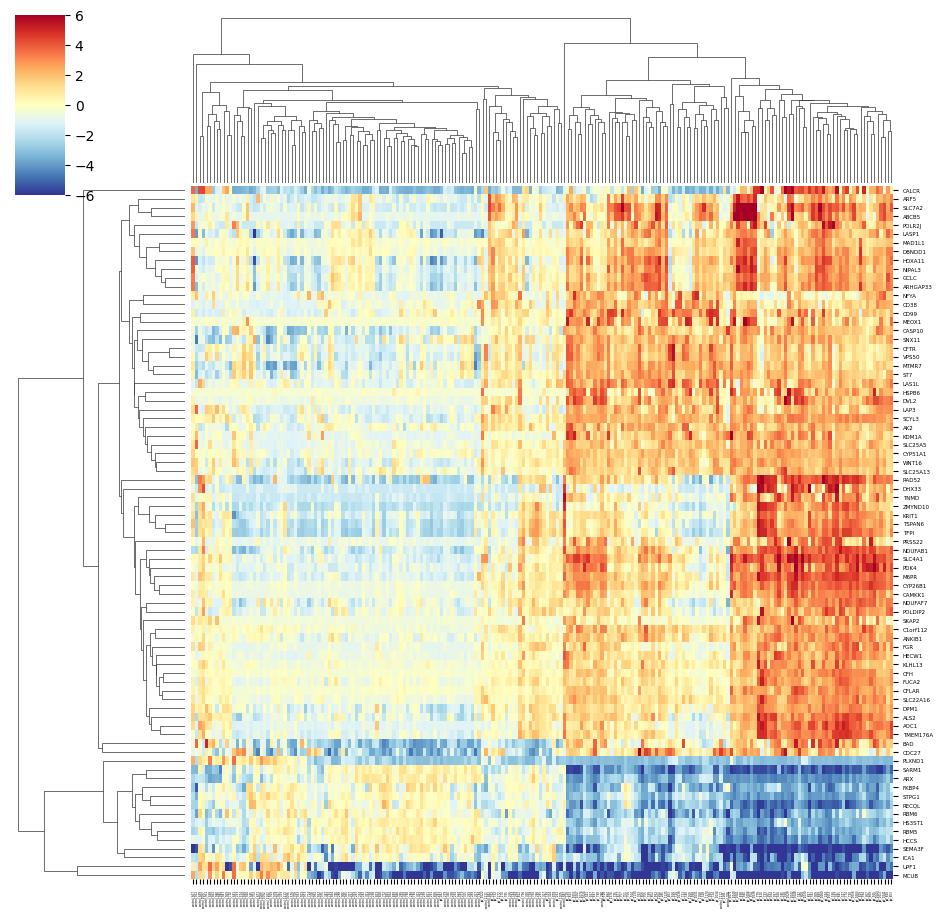

In [133]:
sns_plot = sns.clustermap(
    corr,
    cmap="RdYlBu_r",      
    cbar=True,  
    xticklabels=corr.columns,  
    yticklabels=genes,  
    vmin=-6, vmax=6,  
)

sns_plot.ax_heatmap.set_xticklabels(sns_plot.ax_heatmap.get_xmajorticklabels(), fontsize=2)
sns_plot.ax_heatmap.set_yticklabels(sns_plot.ax_heatmap.get_ymajorticklabels(), fontsize=4)

sns_plot.savefig("../data/GSE150910/heatmap.pdf", dpi=300)
sns_plot.savefig("../data/GSE150910/heatmap.png", dpi=300)
plt.show()

6374

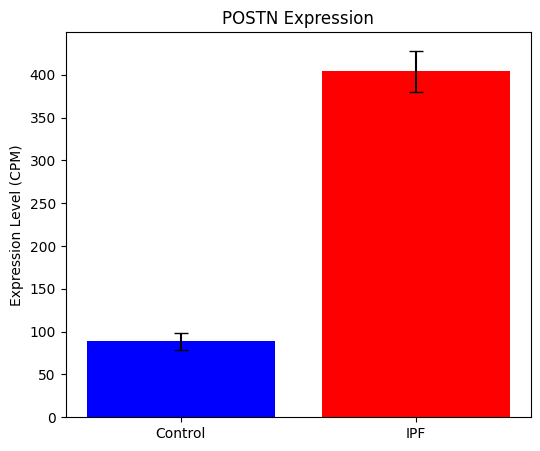

In [144]:
gene_to_plot = 'POSTN' 
gene_idx = main_df['symbol'].values.tolist().index(gene_to_plot)

control_cols = sig_genes.filter(regex='control').columns
ipf_cols = sig_genes.filter(regex='ipf').columns

control_expression = sig_genes.loc[gene_idx, control_cols].to_numpy(
    dtype=float
)
ipf_expression = sig_genes.loc[gene_idx, ipf_cols].to_numpy(dtype=float)

control_mean = np.mean(control_expression)
control_sem = np.std(control_expression) / np.sqrt(len(control_expression))

ipf_mean = np.mean(ipf_expression)
ipf_sem = np.std(ipf_expression) / np.sqrt(len(ipf_expression))

conditions = ['Control', 'IPF']
means = [control_mean, ipf_mean]
errors = [control_sem, ipf_sem]

plt.figure(figsize=(6, 5))
plt.bar(conditions, means, yerr=errors, capsize=5, color=['blue', 'red'])
plt.ylabel('Expression Level (CPM)')
plt.title(f'{gene_to_plot} Expression')

plt.show()

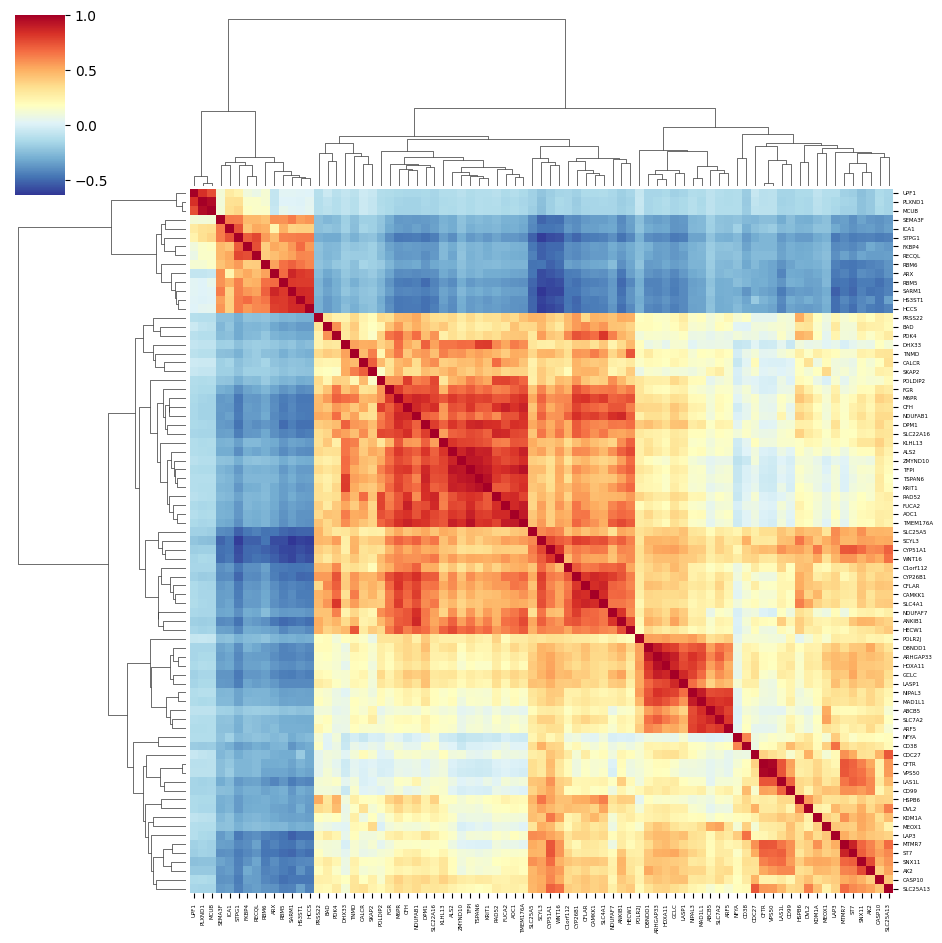

In [149]:
corr = sig_genes.T.corr()

sns_plot = sns.clustermap(
    corr,
    cmap="RdYlBu_r",      
    cbar=True,  
    xticklabels=genes,  
    yticklabels=genes,  
)

sns_plot.ax_heatmap.set_xticklabels(sns_plot.ax_heatmap.get_xmajorticklabels(), fontsize=4)
sns_plot.ax_heatmap.set_yticklabels(sns_plot.ax_heatmap.get_ymajorticklabels(), fontsize=4)

sns_plot.savefig("../data/GSE150910/corr_heatmap.pdf", dpi=300)
sns_plot.savefig("../data/GSE150910/corr_heatmap.png", dpi=300)
plt.show()